In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# KAN-25 · Dataset dan Training Model Regresi Durasi

## Bagian A · OULAD

**Dataset:** Open University Learning Analytics Dataset (OULAD)
**Sumber:** https://research.stem.open.ac.uk/ouanalyse/open-dataset-more/
**Lisensi:** CC-BY 4.0
**Lokasi lokal:** `datasheet/raw/oulad/` (tidak di-commit)

In [2]:
RAW = Path("../datasheet/raw/oulad")

files = ["assessments", "courses", "studentAssessment", "studentInfo", "studentRegistration", "vle"]
df = {name: pd.read_csv(RAW / f"{name}.csv") for name in files}

for name, d in df.items():
    print(f"\n=== {name} | {d.shape[0]:,} baris x {d.shape[1]} kolom")
    na = d.isna().sum()
    na = na[na > 0]
    print(na.to_string() if len(na) else "tidak ada missing value")


=== assessments | 206 baris x 6 kolom
date    11

=== courses | 22 baris x 3 kolom
tidak ada missing value

=== studentAssessment | 173,912 baris x 5 kolom
score    173

=== studentInfo | 32,593 baris x 12 kolom
imd_band    1111

=== studentRegistration | 32,593 baris x 5 kolom
date_registration         45
date_unregistration    22521

=== vle | 6,364 baris x 6 kolom
week_from    5243
week_to      5243


In [3]:
asm = df["assessments"]
sa = df["studentAssessment"]

print("=== Jenis assessment:")
print(asm["assessment_type"].value_counts(), "\n")

print("=== Assessment yang date-nya kosong:")
print(asm[asm["date"].isna()]["assessment_type"].value_counts(), "\n")

print("=== Contoh isi studentAssessment:")
print(sa.head(), "\n")

print("=== is_banked:")
print(sa["is_banked"].value_counts())

=== Jenis assessment:
assessment_type
TMA     106
CMA      76
Exam     24
Name: count, dtype: int64 

=== Assessment yang date-nya kosong:
assessment_type
Exam    11
Name: count, dtype: int64 

=== Contoh isi studentAssessment:
   id_assessment  id_student  date_submitted  is_banked  score
0           1752       11391              18          0   78.0
1           1752       28400              22          0   70.0
2           1752       31604              17          0   72.0
3           1752       32885              26          0   69.0
4           1752       38053              19          0   79.0 

=== is_banked:
is_banked
0    172003
1      1909
Name: count, dtype: int64


## Cleaning 1: Buang baris banked
Baris `is_banked = 1` adalah nilai yang dibawa dari periode sebelumnya
(mahasiswa mengulang), bukan tugas yang benar-benar dikerjakan.

In [4]:
sa_clean = sa[sa["is_banked"] == 0]
print(len(sa), "→", len(sa_clean))

173912 → 172003


In [5]:
data = sa_clean.merge(asm, on="id_assessment", how="left")

print(data.shape)
print(data["assessment_type"].value_counts())
data.head()

(172003, 10)
assessment_type
TMA     97088
CMA     69956
Exam     4959
Name: count, dtype: int64


,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0


## Cleaning 2: Buang Exam + cek kualitas data
Exam dijadwalkan pada hari yang sama untuk semua mahasiswa,
jadi tidak mencerminkan durasi pengerjaan tugas.

In [6]:
# 1. Buang Exam
data = data[data["assessment_type"] != "Exam"]
print("Jumlah baris:", len(data))
print(data["assessment_type"].value_counts(), "\n")

# 2. Cek: masih ada deadline kosong?
print("Deadline kosong:", data["date"].isna().sum())

# 3. Cek: ada data dobel?
dobel = data.duplicated(subset=["id_student", "id_assessment"]).sum()
print("Baris dobel:", dobel, "\n")

# 4. Hitung selisih hari: deadline - tanggal kumpul
data["hari_sebelum_deadline"] = data["date"] - data["date_submitted"]
data["hari_sebelum_deadline"].describe()

Jumlah baris: 167044
assessment_type
TMA    97088
CMA    69956
Name: count, dtype: int64 

Deadline kosong: 0
Baris dobel: 0 



count    167044.000000
mean         15.885318
std          45.236433
min        -372.000000
25%          -2.000000
50%           1.000000
75%           5.000000
max         246.000000
Name: hari_sebelum_deadline, dtype: float64

## Bagian B · SiP Dataset

**Dataset:** SiP Task Effort Estimation (Software in Partnership Ltd, 2004–2014)
**Sumber:** https://github.com/Derek-Jones/SiP_dataset
**Lisensi:** CC BY-NC-ND 4.0 (data tidak boleh disebarkan ulang, termasuk hasil cleaning)
**Lokasi lokal:** `datasheet/raw/sip/`

In [2]:
SIP = Path("../datasheet/raw/sip")

sip = pd.read_csv(SIP / "Sip-task-info.csv", encoding="latin-1")
sip_dates = pd.read_csv(SIP / "est-act-dates.csv", encoding="latin-1")

for name, d in {"sip": sip, "sip_dates": sip_dates}.items():
    print(f"\n=== {name} | {d.shape[0]:,} baris x {d.shape[1]} kolom")
    na = d.isna().sum()
    na = na[na > 0]
    print(na.to_string() if len(na) else "tidak ada missing value")

sip.head()


=== sip | 12,299 baris x 17 kolom
AuthorisedByID          8034
DeveloperPerformance    2099

=== sip_dates | 12,299 baris x 4 kolom
StartedOn       353
CompletedOn    2586


,TaskNumber,Summary,Priority,RaisedByID,AssignedToID,AuthorisedByID,StatusCode,ProjectCode,ProjectBreakdownCode,Category,SubCategory,HoursEstimate,HoursActual,DeveloperID,DeveloperHoursActual,TaskPerformance,DeveloperPerformance
0,1735,Flag RI on SCM Message Summary screen using me...,1,58,58,6.0,FINISHED,PC2,PBC42,Development,Enhancement,14.0,1.75,58,1.75,12.25,12.25
1,1742,Allow RI Policies to be marked as Exhausted,1,58,42,6.0,FINISHED,PC2,PBC21,Development,Enhancement,7.0,7.00,42,7.00,0.00,0.00
2,1971,Fix Invalid UWREF Line DX402L99A1N,2,7,58,6.0,FINISHED,PC2,PBC75,Operational,In House Support,0.7,0.70,58,0.70,0.00,0.00
3,2134,New rows in the diary event for the SCM are re...,5,50,42,6.0,FINISHED,PC2,PBC42,Development,Bug,0.7,0.70,42,0.70,0.00,0.00
4,2251,Application Screen Size - Need to set Min Size...,10,46,13,6.0,FINISHED,PC2,PBC21,Development,Bug,3.5,3.50,13,3.50,0.00,0.00


In [3]:
print("=== Status tugas:")
print(sip["StatusCode"].value_counts(), "\n")

print("=== Bukti TaskPerformance = HoursEstimate - HoursActual:")
selisih = (sip["HoursEstimate"] - sip["HoursActual"] - sip["TaskPerformance"]).abs()
print("Jumlah baris yang TIDAK cocok:", (selisih > 0.01).sum(), "\n")

print("=== Tugas yang muncul lebih dari sekali:")
dobel = sip["TaskNumber"].value_counts()
print("Jumlah tugas dobel:", (dobel > 1).sum())
sip[sip["TaskNumber"] == dobel.index[0]][["TaskNumber", "DeveloperID", "HoursActual", "DeveloperHoursActual"]]

=== Status tugas:
StatusCode
FINISHED     4950
COMPLETED    4453
CHRONICLE    2323
RELEASED      288
CANCELLED     190
ESTIMATED      86
TEMPLATE        7
AUTHORISE       2
Name: count, dtype: int64 

=== Bukti TaskPerformance = HoursEstimate - HoursActual:
Jumlah baris yang TIDAK cocok: 0 

=== Tugas yang muncul lebih dari sekali:
Jumlah tugas dobel: 1384


,TaskNumber,DeveloperID,HoursActual,DeveloperHoursActual
3762,6889,13,8.0,1.0
3763,6889,24,8.0,1.0
3764,6889,26,8.0,1.0
3765,6889,42,8.0,1.0
3766,6889,43,8.0,1.0
3767,6889,54,8.0,1.0
3768,6889,58,8.0,1.0
3769,6889,65,8.0,1.0


### Cleaning SiP
1. Hanya tugas yang selesai (FINISHED, COMPLETED, RELEASED)
2. Buang kolom leakage (TaskPerformance, DeveloperPerformance) dan kolom administrasi (AuthorisedByID)
3. Hanya tugas yang dikerjakan 1 orang, supaya sesuai dengan pengguna PandAI (individu)

In [4]:
# Cleaning SiP 1: hanya tugas yang benar-benar selesai
selesai = ["FINISHED", "COMPLETED", "RELEASED"]
sip_clean = sip[sip["StatusCode"].isin(selesai)]
print("Setelah filter status :", len(sip_clean))

# Cleaning SiP 2: buang kolom leakage & administrasi
sip_clean = sip_clean.drop(columns=["TaskPerformance", "DeveloperPerformance", "AuthorisedByID"])

# Cleaning SiP 3: hanya tugas yang dikerjakan 1 orang
jumlah_orang = sip_clean.groupby("TaskNumber")["DeveloperID"].transform("size")
sip_clean = sip_clean[jumlah_orang == 1]
print("Setelah filter 1 orang:", len(sip_clean))
print("Total:", len(sip), "→", len(sip_clean))

Setelah filter status : 9691
Setelah filter 1 orang: 7176
Total: 12299 → 7176


### Cek tugas super cepat (< 6 menit)
Temuan: sebagian adalah perubahan tampilan kecil yang dikerjakan sekaligus
(TaskNumber 5053–5062, masing-masing dicatat 3 menit), sisanya catatan
administratif (mis. estimasi & aktual sama-sama 36 detik).

In [5]:
pd.set_option("display.max_colwidth", 80)

cepat = sip_clean[sip_clean["HoursActual"] < 0.1]
cepat[["TaskNumber", "Summary", "SubCategory", "HoursEstimate", "HoursActual"]].sort_values("HoursActual")

,TaskNumber,Summary,SubCategory,HoursEstimate,HoursActual
486,3473,XXXX User Licencing not working (User YYY ZZZ and YYY ZZZ),In House Support,0.50,0.01
6582,9506,Risk Status Flow Needs Defining,Business Specification,0.01,0.01
1963,5053,MOA Change values in Drop Down Box,Enhancement,0.50,0.05
605,3627,Task System Licence,In House Support,0.05,0.05
1967,5057,Remove FIL code from Section,Enhancement,0.50,0.05
1965,5055,Remove Loss Basis from Section,Enhancement,0.50,0.05
1968,5058,"Trustfund on Section, just show code with ToolTip hover",Enhancement,1.00,0.05
1964,5054,Rename Area to Domicile in Section,Enhancement,0.50,0.05
1972,5062,Premium Line % and Written Line % on Line not used,Enhancement,1.00,0.05
1969,5059,"Limit and Excess, provide tooltip for column #",Enhancement,0.50,0.05


### Cek outlier durasi SiP

count    7176.00
mean        5.08
std        12.43
min         0.01
25%         0.75
50%         2.00
75%         4.25
max       339.90
Name: HoursActual, dtype: float64

Batas atas IQR : 9.5 jam → dibuang: 786
Batas domain 40 jam      → dibuang: 126
Kurang dari 6 menit       : 13


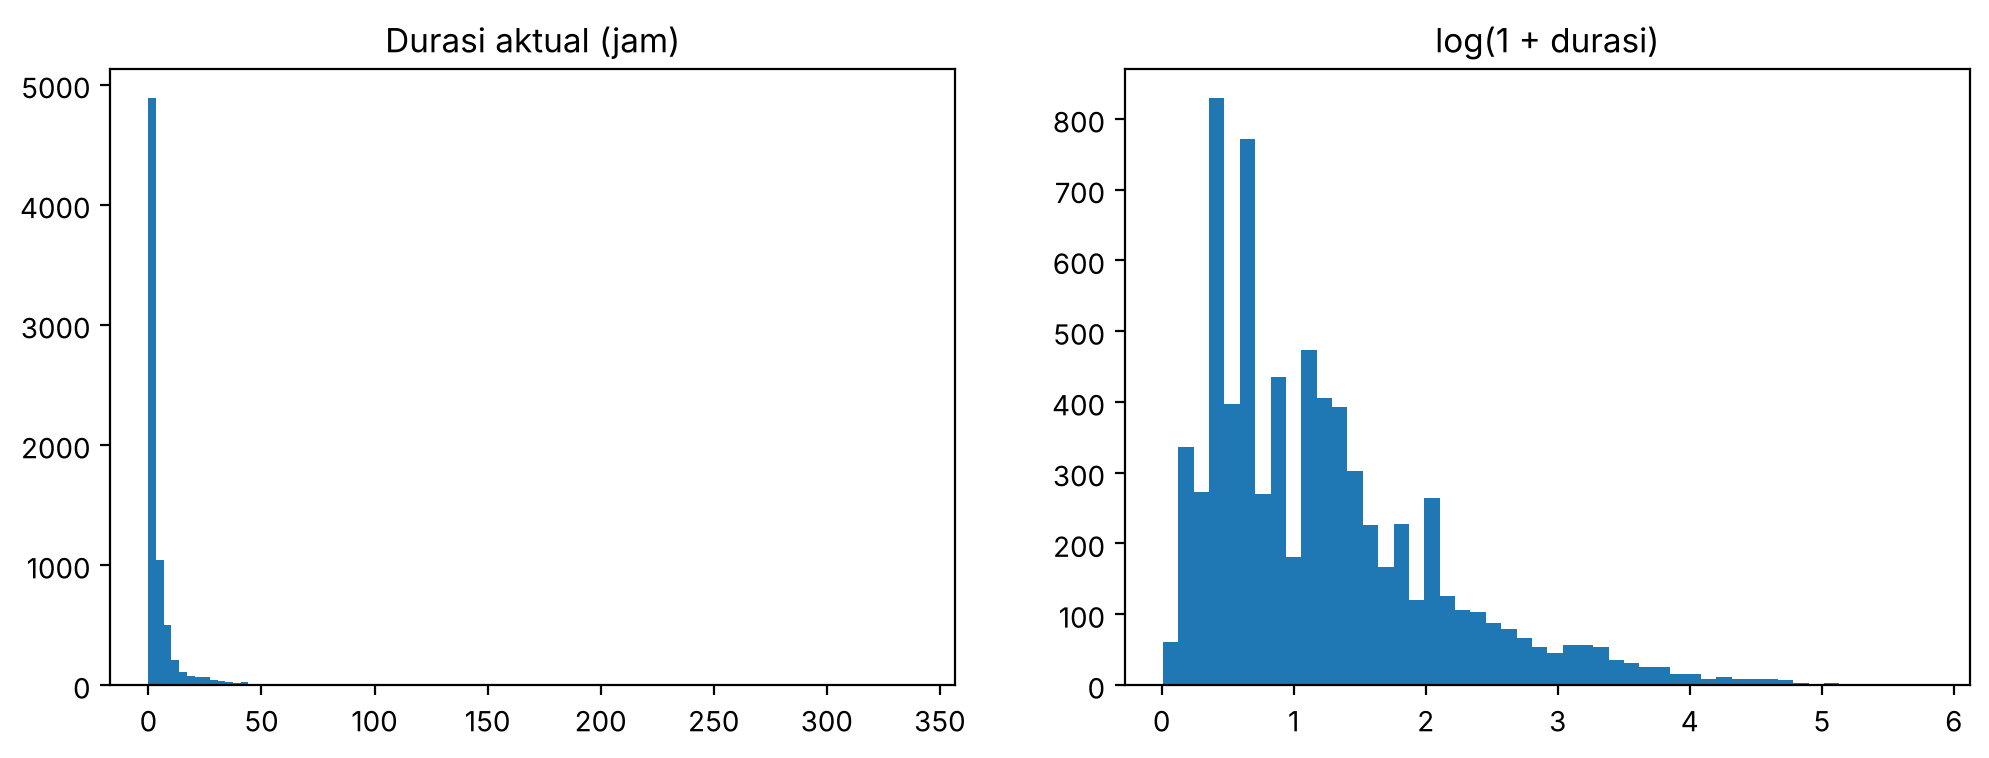

In [6]:
jam = sip_clean["HoursActual"]
print(jam.describe().round(2))

q1, q3 = jam.quantile([0.25, 0.75])
batas_iqr = q3 + 1.5 * (q3 - q1)
print("\nBatas atas IQR :", batas_iqr, "jam → dibuang:", (jam > batas_iqr).sum())
print("Batas domain 40 jam      → dibuang:", (jam > 40).sum())
print("Kurang dari 6 menit       :", (jam < 0.1).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(jam, bins=100)
ax[0].set_title("Durasi aktual (jam)")
ax[1].hist(np.log1p(jam), bins=50)
ax[1].set_title("log(1 + durasi)")
plt.show()

### Cleaning SiP 4: Outlier durasi
- Batas atas **40 jam** (pengetahuan domain), bukan IQR (9,5 jam). Data sangat
  right-skewed, dan tugas kuliah besar wajar dikerjakan 10–15 jam.
- Tugas > 40 jam terbukti berupa **proyek** (rentang median 48 hari,
  mis. "Tasks From Meeting"), bukan tugas tunggal. Tugas raksasa
  dipecah di sisi aplikasi.
- Batas bawah **0,1 jam (6 menit)**: data tidak akurat / bukan tugas sungguhan,
  dan terlalu kecil untuk dijadwalkan.
- Hasil: 7.176 → 7.037 baris.

In [7]:
sip_clean = sip_clean[(sip_clean["HoursActual"] >= 0.1) & (sip_clean["HoursActual"] <= 40)]
print(len(sip_clean))   # → 7037

7037


In [8]:
# Eksplorasi fitur: kolom SiP mana yang bisa jadi input PandAI?

print("=== Category:")
print(sip_clean["Category"].value_counts(), "\n")

print("=== SubCategory (15 teratas):")
print(sip_clean["SubCategory"].value_counts().head(15), "\n")

print("=== Priority:")
print(sip_clean["Priority"].value_counts().sort_index(), "\n")

# Apakah durasi beda-beda antar kategori?
print("=== Durasi per Category:")
print(sip_clean.groupby("Category")["HoursActual"]
      .agg(["count", "median", "mean"]).round(2).sort_values("median"), "\n")

# Seberapa kuat estimasi awal memprediksi durasi aktual?
rho = sip_clean["HoursEstimate"].corr(sip_clean["HoursActual"], method="spearman")
print("Korelasi Spearman HoursEstimate vs HoursActual:", round(rho, 3))

=== Category:
Category
Development    4754
Operational    1336
Management      947
Name: count, dtype: int64 

=== SubCategory (15 teratas):
SubCategory
Enhancement               1599
Bug                       1564
In House Support           861
Support                    824
Client Support             441
Release                    367
Marketing                  358
General Documentation      203
Management Meeting         142
Testing                    135
Training                   112
Project Management          57
Progress Meeting            54
Business Specification      46
Documentation               46
Name: count, dtype: int64 

=== Priority:
Priority
1     4336
2      569
3     1058
4      252
5      631
6       56
7       35
8       32
9       16
10      52
Name: count, dtype: int64 

=== Durasi per Category:
             count  median  mean
Category                        
Operational   1336    1.50  3.37
Development   4754    1.60  3.75
Management     947    2.75  4.93 



Korelasi Spearman HoursEstimate vs HoursActual: 0.857


In [9]:
# Draft pemetaan SubCategory SiP -> type PandAI
peta_type = {
    "Enhancement": "coding", "Bug": "coding", "Release": "coding",
    "Conversion": "coding",
    "General Documentation": "laporan", "Documentation": "laporan",
    "Business Specification": "laporan", "Technical Specification": "laporan",
    "Research": "laporan",
    "Marketing": "presentasi", "Training": "presentasi",
    "Testing": "praktikum",
}

sip_model = sip_clean[sip_clean["SubCategory"].isin(peta_type.keys())].copy()
sip_model["type"] = sip_model["SubCategory"].map(peta_type)
print("Baris:", len(sip_clean), "→", len(sip_model), "\n")

print("=== Durasi per type:")
print(sip_model.groupby("type")["HoursActual"]
      .agg(["count", "median", "mean"]).round(2), "\n")

# size_level 1-3: posisi HoursEstimate di dalam type-nya sendiri (persentil)
pct = sip_model.groupby("type")["HoursEstimate"].rank(pct=True)
sip_model["size_level"] = np.select([pct <= 1/3, pct <= 2/3], [1, 2], default=3)

print("=== Median durasi per type x size_level:")
print(sip_model.groupby(["type", "size_level"])["HoursActual"].median().unstack().round(2))

Baris: 7037 → 4486 

=== Durasi per type:
            count  median  mean
type                           
coding       3541     2.0  4.17
laporan       340     2.7  7.45
praktikum     135     3.0  5.87
presentasi    470     3.0  4.02 

=== Median durasi per type x size_level:
size_level     1    2      3
type                        
coding      0.70  2.0   6.50
laporan     0.81  2.7  16.91
praktikum   1.00  3.5   7.50
presentasi  1.50  3.0   5.00


In [16]:
# === Bagian C · Pengali course_mastery dari OULAD ===
kunci_mk = ["id_student", "code_module", "code_presentation"]

oa = (data.dropna(subset=["score", "date"])
          .sort_values(kunci_mk + ["date"])
          .copy())
grp = oa.groupby(kunci_mk)

# Rata-rata nilai dari tugas-tugas SEBELUMNYA saja (tanpa tugas ini)
jumlah_skor_sebelumnya = grp["score"].cumsum() - oa["score"]
jumlah_tugas_sebelumnya = grp.cumcount()
oa["skor_sebelumnya"] = jumlah_skor_sebelumnya / jumlah_tugas_sebelumnya.replace(0, np.nan)
oa["deadline_sebelumnya"] = grp["date"].shift(1)

# Tugas pertama gak punya riwayat, jadi dibuang
oa = oa.dropna(subset=["skor_sebelumnya", "deadline_sebelumnya"])

oa["mastery"] = pd.cut(oa["skor_sebelumnya"], bins=[-1, 40, 60, 75, 90, 100],
                       labels=[1, 2, 3, 4, 5]).astype(int)
print("Baris:", len(oa))
print(oa["mastery"].value_counts().sort_index())

Baris: 141336
mastery
1     2975
2    12934
3    37955
4    68507
5    18965
Name: count, dtype: int64


In [17]:
vle = pd.read_csv(RAW / "studentVle.csv",
                  usecols=["code_module", "code_presentation", "id_student", "date", "sum_click"],
                  dtype={"code_module": "category", "code_presentation": "category",
                         "id_student": "int32", "date": "int16", "sum_click": "int32"})
print("studentVle:", f"{len(vle):,} baris")

# Ringkas jadi total klik per mahasiswa per hari, lalu jumlah kumulatifnya
harian = (vle.groupby(kunci_mk + ["date"], observed=True)["sum_click"].sum()
             .reset_index())
del vle
harian["kunci"] = harian["code_module"].astype(str) + "_" + harian["code_presentation"].astype(str)
harian = harian.sort_values(["id_student", "kunci", "date"])
harian["klik_kumulatif"] = harian.groupby(["id_student", "kunci"])["sum_click"].cumsum()
harian["date"] = harian["date"].astype("int64")

oa["kunci"] = oa["code_module"].astype(str) + "_" + oa["code_presentation"].astype(str)

def klik_sampai(df, kolom_hari):
    """Total klik kumulatif mahasiswa sampai hari tertentu."""
    kiri = (df[["id_student", "kunci", kolom_hari]]
              .rename(columns={kolom_hari: "date"})
              .astype({"date": "int64", "id_student": "int64"})
              .reset_index())
    kanan = harian[["id_student", "kunci", "date", "klik_kumulatif"]].astype({"id_student": "int64"})
    hasil = pd.merge_asof(kiri.sort_values("date"), kanan.sort_values("date"),
                          on="date", by=["id_student", "kunci"], direction="backward")
    return hasil.set_index("index")["klik_kumulatif"].reindex(df.index).fillna(0)

# Klik di antara deadline sebelumnya dan deadline tugas ini
oa["klik_jendela"] = klik_sampai(oa, "date") - klik_sampai(oa, "deadline_sebelumnya")
print(oa["klik_jendela"].describe().round(1))

studentVle: 10,655,280 baris
count    141336.0
mean        192.2
std         331.5
min           0.0
25%           0.0
50%          64.0
75%         232.0
max        7557.0
Name: klik_jendela, dtype: float64


In [18]:
# Hanya tugas yang benar-benar diselesaikan dengan lulus (seperti tugas di PandAI)
oa = oa[oa["score"] >= 40]

# Normalisasi: tiap tugas beda beban, jadi bandingkan dengan median tugas yang sama
median_per_tugas = oa.groupby("id_assessment")["klik_jendela"].transform("median")
oa = oa[median_per_tugas > 0].copy()
oa["rasio_usaha"] = oa["klik_jendela"] / median_per_tugas[median_per_tugas > 0]

ringkas = oa.groupby("mastery")["rasio_usaha"].agg(["count", "median"])
ringkas["pengali_vs_level3"] = ringkas["median"] / ringkas.loc[3, "median"]
print(ringkas.round(2))

rho = oa["skor_sebelumnya"].corr(oa["rasio_usaha"], method="spearman")
print("Spearman skor_sebelumnya vs rasio_usaha:", round(rho, 3))

         count  median  pengali_vs_level3
mastery                                  
1         2184    0.86               0.99
2         9001    0.78               0.91
3        24502    0.86               1.00
4        41718    1.05               1.21
5        14301    1.25               1.45
Spearman skor_sebelumnya vs rasio_usaha: 0.176


In [19]:
# Koreksi engagement: bandingkan tiap mahasiswa dengan kebiasaannya sendiri
kel = oa.groupby(kunci_mk)
oa["baseline_rajin"] = kel["rasio_usaha"].transform("median")
oa["n_tugas"] = kel["rasio_usaha"].transform("size")

w = oa[(oa["n_tugas"] >= 3) & (oa["baseline_rajin"] > 0)].copy()
w["usaha_relatif"] = w["rasio_usaha"] / w["baseline_rajin"]
w["usaha_relatif"] = w["usaha_relatif"].clip(upper=w["usaha_relatif"].quantile(0.99))
w["selisih_skor"] = w["skor_sebelumnya"] - w.groupby(kunci_mk)["skor_sebelumnya"].transform("mean")

print("Mahasiswa-matkul dianalisis:", w.groupby(kunci_mk).ngroups, "| baris:", len(w))

rk = w.groupby("mastery")["usaha_relatif"].agg(["count", "median", "mean"])
rk["pengali_vs_level3"] = rk["mean"] / rk.loc[3, "mean"]
print(rk.round(2))

rho_dalam = w["selisih_skor"].corr(w["usaha_relatif"], method="spearman")
print("Spearman DALAM mahasiswa yang sama:", round(rho_dalam, 3))

Mahasiswa-matkul dianalisis: 18102 | baris: 84890
         count  median  mean  pengali_vs_level3
mastery                                        
1         1529     1.0  1.14               1.02
2         7507     1.0  1.16               1.04
3        22435     1.0  1.12               1.00
4        39749     1.0  1.09               0.97
5        13670     1.0  1.10               0.98
Spearman DALAM mahasiswa yang sama: -0.006


## Model Registry (versi ringan, berbasis file)
Setiap model disimpan sebagai file sendiri: `pandai_model_v1.pkl`, `pandai_model_v2.pkl`, dst.
`registry.json` mencatat metadata tiap versi + versi mana yang **aktif** dipakai FastAPI.
- Versi lama **tidak pernah ditimpa** (kalau nama versi sudah ada → error)
- Ganti/rollback model cukup ubah `aktif` (atau env `MODEL_VERSION`), tanpa training ulang
- `sha256` dipakai FastAPI untuk memastikan file model tidak rusak/tertukar

In [10]:
import json, hashlib, joblib
from datetime import datetime
from pathlib import Path

FOLDER_MODEL = Path(globals().get("FOLDER_MODEL", "../ml-service/models"))
REGISTRY = FOLDER_MODEL / "registry.json"


def _sha256(file: Path) -> str:
    return hashlib.sha256(file.read_bytes()).hexdigest()


def baca_registry() -> dict:
    if REGISTRY.exists():
        return json.loads(REGISTRY.read_text(encoding="utf-8"))
    return {"aktif": None, "versi": {}}


def _tulis_registry(reg: dict):
    FOLDER_MODEL.mkdir(parents=True, exist_ok=True)
    REGISTRY.write_text(json.dumps(reg, indent=2, ensure_ascii=False), encoding="utf-8")


def _catat(versi: str, file: Path, paket: dict, catatan: str, aktifkan: bool):
    reg = baca_registry()
    meta = paket["metadata"]
    reg["versi"][versi] = {
        "file": file.name,
        "sha256": _sha256(file),
        "nama": meta.get("versi"),
        "dilatih_pada": meta.get("dilatih_pada"),
        "didaftarkan_pada": datetime.now().isoformat(timespec="seconds"),
        "sklearn": meta.get("sklearn"),
        "hyperparameter": meta.get("hyperparameter"),
        "evaluasi_test": meta.get("evaluasi_test"),
        "evaluasi_cv_mae": meta.get("evaluasi_cv_mae"),
        "catatan": catatan,
    }
    if aktifkan or reg["aktif"] is None:
        reg["aktif"] = versi
    _tulis_registry(reg)
    print(f"✔ {versi} tercatat ({file.name}, {file.stat().st_size / 1024:.0f} KB)"
          f"{' · AKTIF' if reg['aktif'] == versi else ''}")


def _cek_versi_baru(versi: str) -> Path:
    file = FOLDER_MODEL / f"pandai_model_{versi}.pkl"
    if versi in baca_registry()["versi"] or file.exists():
        raise FileExistsError(f"Versi '{versi}' sudah ada. Pakai nama baru (mis. v3), jangan menimpa.")
    return file


def simpan_versi(paket: dict, versi: str, catatan: str = "", aktifkan: bool = True):
    """Simpan model hasil training sebagai versi baru."""
    file = _cek_versi_baru(versi)
    FOLDER_MODEL.mkdir(parents=True, exist_ok=True)
    joblib.dump(paket, file)
    _catat(versi, file, paket, catatan, aktifkan)


def daftarkan_file_lama(nama_file: str, versi: str, catatan: str = "", aktifkan: bool = False):
    """Daftarkan model yang SUDAH ada (mis. pandai_model.pkl dari v1) tanpa training ulang.
    File di-rename (bukan disalin) supaya isinya identik byte-per-byte."""
    lama = FOLDER_MODEL / nama_file
    file = _cek_versi_baru(versi)
    paket = joblib.load(lama)              # pastikan file valid sebelum dipindah
    lama.rename(file)
    _catat(versi, file, paket, catatan, aktifkan)


def aktifkan_versi(versi: str):
    """Ganti model yang dipakai FastAPI (berlaku setelah server di-restart)."""
    reg = baca_registry()
    if versi not in reg["versi"]:
        raise KeyError(f"Versi '{versi}' tidak ada. Tersedia: {list(reg['versi'])}")
    reg["aktif"] = versi
    _tulis_registry(reg)
    print("Versi aktif sekarang:", versi)


def lihat_registry():
    reg = baca_registry()
    baris = [{"versi": v + (" ⭐" if v == reg["aktif"] else ""), "nama": i["nama"],
              "MAE test": (i["evaluasi_test"] or {}).get("MAE_jam"),
              "R²": (i["evaluasi_test"] or {}).get("R2"),
              "cakupan %": (i["evaluasi_test"] or {}).get("cakupan_rentang_persen"),
              "CV MAE": i.get("evaluasi_cv_mae"), "dilatih": i["dilatih_pada"], "catatan": i["catatan"]}
             for v, i in reg["versi"].items()]
    return pd.DataFrame(baris)

In [11]:
# ⚠️ JALANKAN SEKALI SAJA, SEBELUM training v2:
# pindahkan model v1 yang sekarang (pandai_model.pkl) menjadi pandai_model_v1.pkl + catat di registry
if (FOLDER_MODEL / "pandai_model.pkl").exists() and "v1" not in baca_registry()["versi"]:
    daftarkan_file_lama("pandai_model.pkl", "v1",
                        catatan="GradientBoosting, target log, loss squared_error (cold start SiP)",
                        aktifkan=True)
lihat_registry()

✔ v1 tercatat (pandai_model_v1.pkl, 568 KB) · AKTIF


,versi,nama,MAE test,R²,cakupan %,CV MAE,dilatih,catatan
0,v1 ⭐,v1-coldstart-sip,1.885,0.513,78.7,None,2026-11-17T15:15:05,"GradientBoosting, target log, loss squared_error (cold start SiP)"


## Bagian D · Improvement Model (v2)
Perubahan dari v1:
1. **size_pct tanpa leakage**: persentil dihitung dari data train saja
2. **Evaluasi repeated K-Fold (5×5) + uji berpasangan**, bukan cuma 1 kali split
3. **HistGradientBoosting + monotonic constraint**: ukuran naik → durasi tidak turun
4. **loss = absolute_error**: model langsung mengoptimalkan MAE (metrik utama kita)
5. **Rentang min-max dikalibrasi dengan Conformal Quantile Regression (CQR)**
6. **Seleksi model menyeluruh (D4b)**: 7 jenis model × scaler × transformasi target = 750 kombinasi

In [12]:
import json, joblib, sklearn
from datetime import datetime
from scipy.stats import wilcoxon
from sklearn.model_selection import train_test_split, GridSearchCV, RepeatedKFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

y = sip_model["HoursActual"]
idx_train, idx_test = train_test_split(sip_model.index, test_size=0.2, random_state=42,
                                       stratify=sip_model["type"])

# D1 · size_pct TANPA leakage: posisi tiap tugas dibandingkan distribusi TRAIN saja
# (v1 memakai rank() di seluruh data, sehingga data test ikut "mengintip")
ref = {t: np.sort(g.values) for t, g in sip_model.loc[idx_train].groupby("type")["HoursEstimate"]}
sip_model["size_pct"] = [np.searchsorted(ref[t], v, side="right") / len(ref[t])
                         for t, v in zip(sip_model["type"], sip_model["HoursEstimate"])]

X = sip_model[["type", "size_pct"]]
X_train, X_test = X.loc[idx_train], X.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
print("Train:", len(X_train), "| Test:", len(X_test))

Train: 3588 | Test: 898


In [13]:
# D2 · Helper pipeline
def pra_type():
    # One-hot type; urutan kolom output: 4 kolom type, lalu size_pct
    return ColumnTransformer([("type", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["type"])],
                             remainder="passthrough")

def pakai_log(pipe):
    # Transformasi log pada TARGET (durasi sangat right-skewed), output tetap dalam jam
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

def buat(model, scaler=None, log=True):
    steps = [("pra", pra_type())] + ([("scale", scaler)] if scaler is not None else []) + [("model", model)]
    return pakai_log(Pipeline(steps)) if log else Pipeline(steps)

GB_V1 = dict(random_state=42, learning_rate=0.05, max_depth=4, min_samples_leaf=30, n_estimators=100)
MONO = [0, 0, 0, 0, 1]   # 0 = bebas (type), 1 = harus naik (size_pct)
CV = RepeatedKFold(n_splits=5, n_repeats=5, random_state=99)   # 25 fold, dipakai SEMUA kandidat

def uji_berpasangan(kandidat, Xd, yd):
    """Semua kandidat dinilai di 25 fold yang SAMA, lalu dibandingkan per fold dengan baseline."""
    skor = {k: [] for k in kandidat}
    for tr, te in CV.split(Xd):
        for k, f in kandidat.items():
            p = f().fit(Xd.iloc[tr], yd.iloc[tr]).predict(Xd.iloc[te])
            skor[k].append(mean_absolute_error(yd.iloc[te], p))
    base = np.array(skor[list(kandidat)[0]])
    baris = []
    for k, s in skor.items():
        s = np.array(s); d = s - base
        baris.append({"Kandidat": k, "MAE (jam)": s.mean(), "±std": s.std(),
                      "Δ vs baseline": d.mean(), "menang /25": int((d < 0).sum()),
                      "p (Wilcoxon)": wilcoxon(d).pvalue if d.any() else np.nan})
    return pd.DataFrame(baris).round(4)

In [14]:
# D3 · Apakah SCALING membantu? (jawab pakai data, bukan asumsi)
# Pohon keputusan memotong fitur berdasarkan URUTAN nilai, jadi scaling tidak mengubah apa pun.
# Scaling baru berpengaruh untuk model berbasis JARAK / regularisasi (SVR, KNN, Ridge).
Xtr_s, ytr_s = X_train.reset_index(drop=True), y_train.reset_index(drop=True)
print(uji_berpasangan({
    "GB tanpa scaler": lambda: buat(GradientBoostingRegressor(**GB_V1)),
    "GB + StandardScaler": lambda: buat(GradientBoostingRegressor(**GB_V1), StandardScaler()),
    "GB + RobustScaler": lambda: buat(GradientBoostingRegressor(**GB_V1), RobustScaler()),
}, Xtr_s, ytr_s).to_string(index=False))
print()
print(uji_berpasangan({
    "SVR tanpa scaler": lambda: buat(SVR()),
    "SVR + StandardScaler": lambda: buat(SVR(), StandardScaler()),
    "SVR + RobustScaler": lambda: buat(SVR(), RobustScaler()),
}, Xtr_s, ytr_s).to_string(index=False))

           Kandidat  MAE (jam)   ±std  Δ vs baseline  menang /25  p (Wilcoxon)
    GB tanpa scaler     2.0987 0.1205         0.0000           0           NaN
GB + StandardScaler     2.0986 0.1205        -0.0001           3        0.1088
  GB + RobustScaler     2.0987 0.1205        -0.0000           2        0.1797



            Kandidat  MAE (jam)   ±std  Δ vs baseline  menang /25  p (Wilcoxon)
    SVR tanpa scaler     2.1444 0.1040         0.0000           0           NaN
SVR + StandardScaler     2.1156 0.1039        -0.0288          25           0.0
  SVR + RobustScaler     2.0951 0.1067        -0.0493          25           0.0


In [15]:
# D4 · Perbandingan kandidat model (di data TRAIN, test tetap disimpan untuk akhir)
hasil_kandidat = uji_berpasangan({
    "v1: GB, log, squared_error": lambda: buat(GradientBoostingRegressor(**GB_V1)),
    "GB, target sqrt": lambda: TransformedTargetRegressor(
        Pipeline([("pra", pra_type()), ("model", GradientBoostingRegressor(**GB_V1))]),
        func=np.sqrt, inverse_func=np.square),
    "HistGB monotonic, squared_error": lambda: buat(HistGradientBoostingRegressor(
        monotonic_cst=MONO, max_iter=200, learning_rate=0.05, min_samples_leaf=30, random_state=42)),
    "HistGB monotonic, absolute_error": lambda: buat(HistGradientBoostingRegressor(
        loss="absolute_error", monotonic_cst=MONO, max_iter=200, learning_rate=0.05,
        min_samples_leaf=30, random_state=42)),
}, Xtr_s, ytr_s)
hasil_kandidat

,Kandidat,MAE (jam),±std,Δ vs baseline,menang /25,p (Wilcoxon)
0,"v1: GB, log, squared_error",2.0987,0.1205,0.0000,0,NaN
1,"GB, target sqrt",2.0807,0.1080,-0.0180,17,0.0034
2,"HistGB monotonic, squared_error",2.0892,0.1102,-0.0095,15,0.2752
3,"HistGB monotonic, absolute_error",2.0573,0.1024,-0.0414,21,0.0000


## D4b · Seleksi model menyeluruh: SEMUA kombinasi dalam satu Pipeline
Bukan cuma angka hyperparameter: **jenis model, scaler, dan transformasi target juga dijadikan
hyperparameter**. `GridSearchCV` lalu mencoba setiap kombinasinya dengan 5-fold CV yang sama.

```
TransformedTargetRegressor(transformer = log / sqrt / tanpa)        ← transformasi target
  └── Pipeline:  pra (one-hot type)  →  scale (Standard / Robust / MinMax / tanpa)  →  model
```
Hasilnya dipakai sebagai BUKTI pemilihan model (lampiran laporan); model final tetap dari D5.
Model pohon hanya dipasangkan dengan "tanpa scaler" karena terbukti (D3) scaling tidak mengubah
hasilnya. Ini menghemat ratusan training yang hasilnya pasti identik.

In [16]:
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.model_selection import KFold, ParameterGrid

# Pilihan transformasi target (dipakai sebagai nilai hyperparameter "transformer")
T_LOG  = FunctionTransformer(np.log1p, inverse_func=np.expm1, check_inverse=False)
T_SQRT = FunctionTransformer(np.sqrt,  inverse_func=np.square, check_inverse=False)
T_NONE = None
SCALERS = [StandardScaler(), RobustScaler(), MinMaxScaler()]

# Kerangka pipeline: isi "scale" & "model" akan ditukar-tukar oleh GridSearchCV
pipa = TransformedTargetRegressor(
    regressor=Pipeline([("pra", pra_type()), ("scale", "passthrough"), ("model", Ridge())]),
    transformer=T_LOG)

m = "regressor__model__"     # prefix nama parameter milik model
ruang = [
    # ---------- model linear & berbasis jarak: scaler berpengaruh ----------
    {"regressor__model": [Ridge()], "regressor__scale": SCALERS,
     "transformer": [T_LOG, T_SQRT, T_NONE], m + "alpha": [0.1, 1, 10, 100]},
    {"regressor__model": [KNeighborsRegressor()], "regressor__scale": SCALERS,
     "transformer": [T_LOG, T_SQRT, T_NONE],
     m + "n_neighbors": [10, 20, 30, 50, 80], m + "weights": ["uniform", "distance"]},
    {"regressor__model": [SVR()], "regressor__scale": [StandardScaler(), RobustScaler()],
     "transformer": [T_LOG, T_SQRT], m + "C": [0.3, 1, 3, 10], m + "epsilon": [0.05, 0.1, 0.3]},
    # ---------- model pohon: scaler tidak berpengaruh → "passthrough" saja ----------
    {"regressor__model": [RandomForestRegressor(n_estimators=300, random_state=42)],
     "regressor__scale": ["passthrough"], "transformer": [T_LOG, T_SQRT, T_NONE],
     m + "min_samples_leaf": [5, 10, 20, 40], m + "max_features": [1.0, 0.6]},
    {"regressor__model": [ExtraTreesRegressor(n_estimators=300, random_state=42)],
     "regressor__scale": ["passthrough"], "transformer": [T_LOG, T_SQRT, T_NONE],
     m + "min_samples_leaf": [5, 10, 20, 40], m + "max_features": [1.0, 0.6]},
    {"regressor__model": [GradientBoostingRegressor(random_state=42)],
     "regressor__scale": ["passthrough"], "transformer": [T_LOG, T_NONE],
     m + "loss": ["squared_error", "absolute_error", "huber"], m + "learning_rate": [0.05, 0.1],
     m + "n_estimators": [100, 300], m + "max_depth": [3, 4], m + "min_samples_leaf": [10, 30]},
    {"regressor__model": [HistGradientBoostingRegressor(random_state=42)],
     "regressor__scale": ["passthrough"], "transformer": [T_LOG, T_SQRT],
     m + "loss": ["squared_error", "absolute_error"], m + "monotonic_cst": [None, MONO],
     m + "learning_rate": [0.03, 0.05, 0.1], m + "max_iter": [100, 200, 400],
     m + "max_leaf_nodes": [7, 15, 31], m + "min_samples_leaf": [10, 30]},
]
n_kombinasi = len(ParameterGrid(ruang))
print(f"{n_kombinasi} kombinasi × 5 fold = {n_kombinasi * 5:,} kali training")

750 kombinasi × 5 fold = 3,750 kali training


In [17]:
# Jalankan pencarian (laptop 8 core: ±10-15 menit; verbose menampilkan progres)
cari_semua = GridSearchCV(pipa, ruang, cv=KFold(n_splits=5, shuffle=True, random_state=42),
                    scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"},
                    refit="MAE", n_jobs=-1, verbose=1, error_score="raise")
cari_semua.fit(X_train, y_train)
print("MAE CV terbaik:", round(-cari_semua.best_score_, 3), "jam")

Fitting 5 folds for each of 750 candidates, totalling 3750 fits


MAE CV terbaik: 2.049 jam


In [18]:
# Leaderboard: rapikan hasil 750 kombinasi jadi tabel yang bisa dibaca
def nama(o):
    if o is None: return "tanpa"
    if isinstance(o, str): return "tanpa" if o == "passthrough" else o
    if isinstance(o, FunctionTransformer): return {np.log1p: "log", np.sqrt: "sqrt"}[o.func]
    return type(o).__name__.replace("Regressor", "").replace("Scaler", "")

hasil = pd.DataFrame(cari_semua.cv_results_)
lb = pd.DataFrame({
    "_i":     hasil.index,                       # penunjuk baris asli di cv_results_
    "model":  hasil["param_regressor__model"].map(nama),
    "scaler": hasil["param_regressor__scale"].map(nama),
    "target": hasil["param_transformer"].map(nama),
    "MAE":    -hasil["mean_test_MAE"], "±std": hasil["std_test_MAE"],
    "RMSE":   -hasil["mean_test_RMSE"], "R2": hasil["mean_test_R2"],
    "detik/fit": hasil["mean_fit_time"],
    "hyperparameter": hasil["params"].map(lambda d: {k.replace(m, ""): (nama(v) if k == m + "monotonic_cst" and v is None else v)
                                                     for k, v in d.items() if k.startswith(m)}),
}).sort_values("MAE").reset_index(drop=True)
lb.index += 1

print("=== Juara tiap jenis model ===")
juara_tiap_model = lb.groupby("model", sort=False).head(1)
print(juara_tiap_model.drop(columns=["_i", "hyperparameter"]).round(3).to_string())
print("\n=== 10 kombinasi terbaik ===")
print(lb.head(10).drop(columns=["_i", "detik/fit"]).round(3).to_string())
lb.drop(columns="_i").to_csv("hasil_tuning_semua_model.csv", index_label="peringkat")   # lampiran laporan

=== Juara tiap jenis model ===
                    model    scaler target    MAE   ±std   RMSE     R2  detik/fit
1    HistGradientBoosting     tanpa    log  2.049  0.177  4.304  0.521      0.510
92             ExtraTrees     tanpa   sqrt  2.071  0.141  4.328  0.515      0.277
110      GradientBoosting     tanpa  tanpa  2.074  0.156  4.424  0.494      0.987
130          RandomForest     tanpa   sqrt  2.077  0.158  4.330  0.515      0.352
180                   SVR    Robust   sqrt  2.082  0.142  4.337  0.514      0.248
232            KNeighbors    MinMax   sqrt  2.085  0.151  4.295  0.523      0.008
715                 Ridge  Standard    log  2.283  0.148  4.838  0.396      0.060

=== 10 kombinasi terbaik ===
                   model scaler target    MAE   ±std   RMSE     R2                                                                                                                                      hyperparameter
1   HistGradientBoosting  tanpa    log  2.049  0.177  4.304  0.521  

In [19]:
# Cek "kutukan pemenang" (winner's curse): dari 750 kombinasi, juara di 5 fold yang SAMA
# bisa menang karena KEBETULAN (fold-nya cocok). Uji ulang di 25 fold BARU yang tidak ikut seleksi.
# Kalau selisihnya tidak signifikan (p > 0.05), pilih yang lebih sederhana / yang sudah tervalidasi.
def dari_peringkat(i):
    """Buat ulang pipeline (belum dilatih) dari kombinasi peringkat ke-i."""
    return lambda: clone(pipa).set_params(**hasil["params"][lb.loc[i, "_i"]])

kandidat = {
    "v1: GB, log, squared_error": lambda: buat(GradientBoostingRegressor(**GB_V1)),
    "v2: HistGB mono abs (lr .1, leaf 31)": lambda: buat(HistGradientBoostingRegressor(
        loss="absolute_error", monotonic_cst=MONO, learning_rate=0.1, max_iter=400,
        max_leaf_nodes=31, min_samples_leaf=10, random_state=42)),
}
for i, r in juara_tiap_model.head(4).iterrows():
    kandidat[f"#{i} {r['model']} · {r['scaler']} · {r['target']}"] = dari_peringkat(i)
uji_final = uji_berpasangan(kandidat, Xtr_s, ytr_s)
uji_final

,Kandidat,MAE (jam),±std,Δ vs baseline,menang /25,p (Wilcoxon)
0,"v1: GB, log, squared_error",2.0987,0.1205,0.0000,0,NaN
1,"v2: HistGB mono abs (lr .1, leaf 31)",2.0499,0.1014,-0.0488,22,0.0000
2,#1 HistGradientBoosting · tanpa · log,2.0561,0.1109,-0.0427,21,0.0000
3,#92 ExtraTrees · tanpa · sqrt,2.0686,0.1049,-0.0301,20,0.0001
4,#110 GradientBoosting · tanpa · tanpa,2.0830,0.1184,-0.0157,18,0.0219
5,#130 RandomForest · tanpa · sqrt,2.0759,0.1038,-0.0229,21,0.0008


In [20]:
# D5 · Tuning detail model terpilih (HistGB monotonic + absolute_error, juara D4 & D4b)
model_dasar = buat(HistGradientBoostingRegressor(loss="absolute_error", monotonic_cst=MONO, random_state=42))
grid = {
    "regressor__model__learning_rate":   [0.03, 0.05, 0.1],
    "regressor__model__max_iter":        [100, 200, 400],
    "regressor__model__min_samples_leaf": [10, 30, 60],
    "regressor__model__max_leaf_nodes":  [7, 15, 31],
}
cari = GridSearchCV(model_dasar, grid, cv=RepeatedKFold(n_splits=5, n_repeats=2, random_state=42),
                    scoring="neg_mean_absolute_error", n_jobs=-1).fit(X_train, y_train)
params = {k.split("__")[-1]: v for k, v in cari.best_params_.items()}
model_final = cari.best_estimator_
print("Parameter terbaik:", params)
print("MAE validasi silang (train):", round(-cari.best_score_, 3), "jam")

Parameter terbaik: {'learning_rate': 0.1, 'max_iter': 400, 'max_leaf_nodes': 31, 'min_samples_leaf': 10}
MAE validasi silang (train): 2.042 jam


In [21]:
# D6 · Running max: loss absolute_error menyesuaikan nilai daun SETELAH pohon dibentuk,
# sehingga constraint monotonic bisa sedikit bocor. Solusinya: ambil nilai maksimum
# prediksi dari ukuran 0 sampai ukuran tugas itu. Logika yang sama dipakai di app.py.
def prediksi_monoton(model, X_):
    out = np.empty(len(X_))
    for i, (t, p) in enumerate(zip(X_["type"], X_["size_pct"])):
        grid_ukuran = pd.DataFrame({"type": t, "size_pct": np.linspace(0, p, 40)})
        out[i] = model.predict(grid_ukuran).max()
    return out

pred = prediksi_monoton(model_final, X_test)
print("=== Evaluasi di data TEST (belum pernah dilihat) ===")
print("MAE :", round(mean_absolute_error(y_test, pred), 3), "jam")
print("RMSE:", round(root_mean_squared_error(y_test, pred), 3), "jam")
print("R²  :", round(r2_score(y_test, pred), 3))

=== Evaluasi di data TEST (belum pernah dilihat) ===
MAE : 1.809 jam
RMSE: 3.985 jam
R²  : 0.566


In [22]:
# D7 · Rentang min-max: model kuantil P10 & P90 + kalibrasi Conformal (CQR)
# Train dibagi lagi: 75% untuk melatih model kuantil, 25% untuk mengukur seberapa meleset.
fit_i, cal_i = train_test_split(idx_train, test_size=0.25, random_state=42,
                                stratify=sip_model.loc[idx_train, "type"])

def model_kuantil(alpha):
    return buat(HistGradientBoostingRegressor(loss="quantile", quantile=alpha, random_state=42, **params))

model_min = model_kuantil(0.10).fit(X.loc[fit_i], y.loc[fit_i])
model_max = model_kuantil(0.90).fit(X.loc[fit_i], y.loc[fit_i])

# Skor conformal: seberapa jauh nilai aktual keluar dari rentang (negatif = di dalam rentang)
lo_c, hi_c = np.log1p(model_min.predict(X.loc[cal_i])), np.log1p(model_max.predict(X.loc[cal_i]))
y_c = np.log1p(y.loc[cal_i].values)
skor_c = np.maximum(lo_c - y_c, y_c - hi_c)
n = len(skor_c)
koreksi_log = float(np.quantile(skor_c, min(1, np.ceil((n + 1) * 0.80) / n)))
print("Koreksi CQR (skala log):", round(koreksi_log, 4))

p_min = np.expm1(np.log1p(model_min.predict(X_test)) - koreksi_log)
p_max = np.expm1(np.log1p(model_max.predict(X_test)) + koreksi_log)
cakupan = ((y_test >= p_min) & (y_test <= p_max)).mean() * 100
print(f"Cakupan rentang di TEST (target 80%): {cakupan:.1f}%")
print(f"Lebar rentang: median {np.median(p_max - p_min):.2f} jam")

Koreksi CQR (skala log): 0.0
Cakupan rentang di TEST (target 80%): 82.0%
Lebar rentang: median 2.50 jam


In [23]:
# D8 · Simpan paket model v2 (struktur sama dengan v1 + koreksi_log)
PENGALI_MASTERY = {1: 1.30, 2: 1.15, 3: 1.00, 4: 0.90, 5: 0.80}   # ASUMSI heuristik, lihat Bagian C
RENTANG_UKURAN = {
    "laporan":    {"satuan": "halaman", "min": 1, "max": 30},
    "presentasi": {"satuan": "slide",   "min": 5, "max": 30},
    "coding":     {"satuan": "soal",    "min": 1, "max": 10},
    "praktikum":  {"satuan": "modul",   "min": 1, "max": 5},
}
paket = {
    "model_estimasi": model_final,
    "model_min": model_min,
    "model_max": model_max,
    "koreksi_log": koreksi_log,
    "pengali_mastery": PENGALI_MASTERY,
    "rentang_ukuran": RENTANG_UKURAN,
    "metadata": {
        "versi": "v2-hgb-mono-mae",
        "dilatih_pada": datetime.now().isoformat(timespec="seconds"),
        "sklearn": sklearn.__version__,
        "fitur": ["type", "size_pct"],
        "hyperparameter": params,
        "evaluasi_test": {
            "MAE_jam": round(mean_absolute_error(y_test, pred), 3),
            "RMSE_jam": round(root_mean_squared_error(y_test, pred), 3),
            "R2": round(r2_score(y_test, pred), 3),
            "cakupan_rentang_persen": round(float(cakupan), 1),
        },
        "evaluasi_cv_mae": round(float(-cari.best_score_), 3),
        "jumlah_data": {"train": len(idx_train), "test": len(idx_test)},
    },
}
# Simpan sebagai VERSI BARU lewat registry (lihat sel "Model Registry"). Tidak menimpa v1.
simpan_versi(paket, "v2",
             catatan="HistGB monotonic + loss absolute_error + size_pct tanpa leakage + rentang CQR",
             aktifkan=True)
lihat_registry()

✔ v2 tercatat (pandai_model_v2.pkl, 3751 KB) · AKTIF


,versi,nama,MAE test,R²,cakupan %,CV MAE,dilatih,catatan
0,v1,v1-coldstart-sip,1.885,0.513,78.7,NaN,2026-11-17T15:15:05,"GradientBoosting, target log, loss squared_error (cold start SiP)"
1,v2 ⭐,v2-hgb-mono-mae,1.809,0.566,82.0,2.042,2026-11-18T08:27:17,HistGB monotonic + loss absolute_error + size_pct tanpa leakage + rentang CQR
